Written By: Radman Ghouchian

Helped by: A.M.Y

# Basics

In [2]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 6.0 MB/s eta 0:00:00


In [118]:
# Basics
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import medmnist

# DeepLearning Models
## Basics
import tensorflow as tf
from tensorflow import keras
from keras import Input
from keras import layers
## Layers & Activations Functions & Initializers & Regularizers
from keras.layers import Dense, Dropout, BatchNormalization, Flatten, Concatenate, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Activation
from keras.activations import silu, swish, selu, leaky_relu, softmax
from keras.initializers import GlorotNormal, HeNormal, LecunNormal
from keras.regularizers import L2
## Loss & Metrics & Optimizers & Models & Callbacks
from keras.optimizers import SGD, AdamW
from keras.losses import SparseCategoricalCrossentropy, CategoricalFocalCrossentropy
from keras.metrics import F1Score, Accuracy, Recall
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from keras.models import Sequential, Model
from keras.optimizers.schedules import CosineDecay
from keras.callbacks import EarlyStopping
## Applications
from keras.applications import MobileNetV3Small, mobilenet_v3, ResNet50V2, resnet_v2

In [7]:
medmnist.INFO['dermamnist']

{'python_class': 'DermaMNIST',
 'description': 'The DermaMNIST is based on the HAM10000, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. The dataset consists of 10,015 dermatoscopic images categorized as 7 different diseases, formulized as a multi-class classification task. We split the images into training, validation and test set with a ratio of 7:1:2. The source images of 3×600×450 are resized into 3×28×28.',
 'url': 'https://zenodo.org/records/10519652/files/dermamnist.npz?download=1',
 'MD5': '0744692d530f8e62ec473284d019b0c7',
 'url_64': 'https://zenodo.org/records/10519652/files/dermamnist_64.npz?download=1',
 'MD5_64': 'b70a2f5635c6199aeaa28c31d7202e1f',
 'url_128': 'https://zenodo.org/records/10519652/files/dermamnist_128.npz?download=1',
 'MD5_128': '2defd784463fa5243564e855ed717de1',
 'url_224': 'https://zenodo.org/records/10519652/files/dermamnist_224.npz?download=1',
 'MD5_224': '8974907d8e169bef5f5b96bc506ae45d',
 'task': 'multi-c

In [9]:
train = medmnist.dataset.DermaMNIST(split = 'train', download=True, size=64)
val = medmnist.dataset.DermaMNIST(split = 'val', download=True, size=64)
test = medmnist.dataset.DermaMNIST(split = 'test', download=True, size=64)

100%|██████████| 100M/100M [00:47<00:00, 2.10MB/s] 


In [10]:
x_train, y_train = train.imgs, train.labels
x_val, y_val = val.imgs, val.labels
x_test, y_test = test.imgs, test.labels

(x_train.shape, y_train.shape), (x_val.shape, y_val.shape), (x_test.shape, y_test.shape)

(((7007, 64, 64, 3), (7007, 1)),
 ((1003, 64, 64, 3), (1003, 1)),
 ((2005, 64, 64, 3), (2005, 1)))

In [83]:
y_train2, y_val2 = tf.keras.utils.to_categorical(y_train, num_classes=7), tf.keras.utils.to_categorical(y_val, num_classes=7)

# DeepLearning Models

## Handmade

In [ ]:
# Didn't have the time!

## Keras Application

### MobiletNet

In [97]:
Mobilenet = MobileNetV3Small(include_top=False, weights='imagenet', input_shape=(64,64,3), dropout_rate=0.15, include_preprocessing=True)

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


In [98]:
Mobilenet.trainable = False
# for layer in Mobilenet.layers[-6:]:
#   layer.trainable = True

In [99]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1)
])

input_layer = Input(shape=(64,64,3))

x = data_augmentation(input_layer)
x = Mobilenet(x)
x = GlobalAveragePooling2D()(x)

# y = Dense(256, activation=leaky_relu, kernel_initializer=HeNormal(), kernel_regularizer=L2(0.005), use_bias=False)(x)
# y = BatchNormalization()(y)

y = Dense(128, activation=leaky_relu, kernel_initializer=HeNormal(), kernel_regularizer=L2(0.01), use_bias=False)(x)
y = BatchNormalization()(y)

# y = Dense(64, activation=leaky_relu, kernel_initializer=HeNormal(), kernel_regularizer=L2(0.01), use_bias=False)(y)
# y = BatchNormalization()(y)

concat_layer = Concatenate()([y, x])
concat_layer = Dropout(0.15)(concat_layer)

final = Dense(256, activation=leaky_relu, kernel_initializer=HeNormal(), kernel_regularizer=L2(0.005))(concat_layer)

x = Dense(7, activation=softmax, kernel_initializer=GlorotNormal(), kernel_regularizer=L2(0.008))(final)

Mobilenet_model = Model(inputs=input_layer, outputs=x, name='Mobilenet1')

In [100]:
LR_scheduler = CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=1000,
    alpha=0.01
)

Mobilenet_model.compile(
    optimizer = AdamW(learning_rate=LR_scheduler),
    loss = CategoricalFocalCrossentropy(),
    metrics = ['accuracy']
)

In [101]:
callbacks = [EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)]

Mobilnet_history4 = Mobilenet_model.fit(
    x_train, y_train2,
    batch_size=128,
    epochs=40,
    validation_data=(x_val, y_val2),
    callbacks=callbacks
)

Epoch 1/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 28s 392ms/step - accuracy: 0.6472 - loss: 3.2049 - val_accuracy: 0.6869 - val_loss: 1.5808
Epoch 2/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 36s 295ms/step - accuracy: 0.7104 - loss: 0.9676 - val_accuracy: 0.7049 - val_loss: 0.5812
Epoch 3/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 22s 400ms/step - accuracy: 0.7059 - loss: 0.4176 - val_accuracy: 0.6969 - val_loss: 0.3210
Epoch 4/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 36s 303ms/step - accuracy: 0.7116 - loss: 0.2632 - val_accuracy: 0.6959 - val_loss: 0.2392
Epoch 5/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 17s 314ms/step - accuracy: 0.7183 - loss: 0.2061 - val_accuracy: 0.7029 - val_loss: 0.2022
Epoch 6/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 19s 296ms/step - accuracy: 0.7231 - loss: 0.1791 - val_accuracy: 0.7089 - val_loss: 0.1810
Epoch 7/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 21s 298ms/step - accuracy: 0.7193 - loss: 0.1663 - val_accuracy: 0.7119 - val_loss: 0.1689
Epoch 8/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 16s 296ms/step - accuracy: 0.7186 - loss: 0.1575 - val_accu

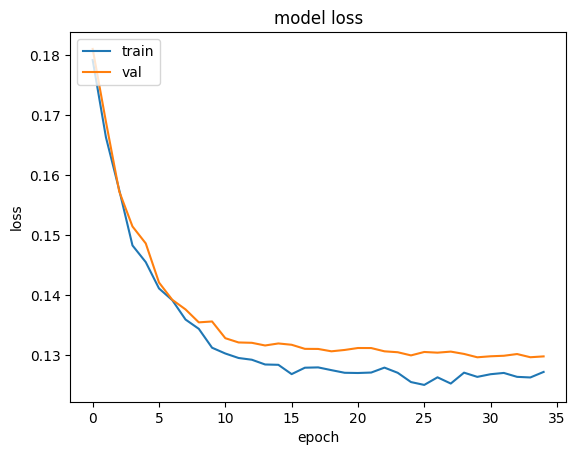

In [105]:
plt.plot(Mobilnet_history4.history['loss'][5:])
plt.plot(Mobilnet_history4.history['val_loss'][5:])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

### Resnet

In [124]:
Resnet = ResNet50V2(include_top=False, weights='imagenet', input_shape=(64,64,3))

In [125]:
Resnet.trainable = False
# for layer in Mobilenet.layers[-6:]:
#   layer.trainable = True

In [126]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1)
])

input_layer = Input(shape=(64,64,3))

x = data_augmentation(input_layer)
x = resnet_v2.preprocess_input(x)
x = Resnet(x)
x = GlobalAveragePooling2D()(x)

# y = Dense(256, activation=leaky_relu, kernel_initializer=HeNormal(), kernel_regularizer=L2(0.005), use_bias=False)(x)
# y = BatchNormalization()(y)

y = Dense(128, activation=leaky_relu, kernel_initializer=HeNormal(), kernel_regularizer=L2(0.01), use_bias=False)(x)
y = BatchNormalization()(y)

# y = Dense(64, activation=leaky_relu, kernel_initializer=HeNormal(), kernel_regularizer=L2(0.01), use_bias=False)(y)
# y = BatchNormalization()(y)

concat_layer = Concatenate()([y, x])
concat_layer = Dropout(0.15)(concat_layer)

final = Dense(256, activation=leaky_relu, kernel_initializer=HeNormal(), kernel_regularizer=L2(0.005))(concat_layer)

x = Dense(7, activation=softmax, kernel_initializer=GlorotNormal(), kernel_regularizer=L2(0.008))(final)

Resnet_model = Model(inputs=input_layer, outputs=x, name='Resnet1')

In [127]:
LR_scheduler = CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=10000,
    alpha=0.01
)

Resnet_model.compile(
    optimizer = AdamW(learning_rate=LR_scheduler),
    loss = CategoricalFocalCrossentropy(),
    metrics = ['accuracy']
)

In [128]:
callbacks = [EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)]

Resnet_history4 = Resnet_model.fit(
    x_train, y_train2,
    batch_size=128,
    epochs=40,
    validation_data=(x_val, y_val2),
    callbacks=callbacks
)

Epoch 1/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.6352 - loss: 2.5175 - val_accuracy: 0.6979 - val_loss: 0.9488
Epoch 2/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.6929 - loss: 0.6461 - val_accuracy: 0.6969 - val_loss: 0.4576
Epoch 3/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.6954 - loss: 0.3843 - val_accuracy: 0.6999 - val_loss: 0.3158
Epoch 4/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.7133 - loss: 0.2800 - val_accuracy: 0.6929 - val_loss: 0.2517
Epoch 5/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.7146 - loss: 0.2301 - val_accuracy: 0.7119 - val_loss: 0.2138
Epoch 6/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 155s 2s/step - accuracy: 0.7119 - loss: 0.2011 - val_accuracy: 0.7308 - val_loss: 0.1853
Epoch 7/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.7119 - loss: 0.1805 - val_accuracy: 0.7149 - val_loss: 0.1715
Epoch 8/40
55/55 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.7144 - loss: 0.1667 - val_accuracy: 0.7308 - va

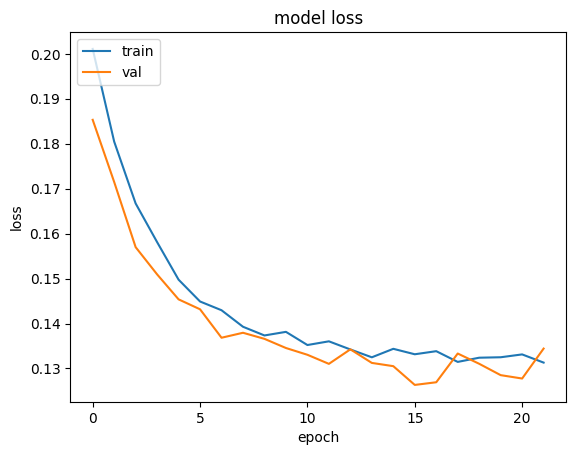

In [132]:
plt.plot(Resnet_history4.history['loss'][5:])
plt.plot(Resnet_history4.history['val_loss'][5:])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

# Evaluation

## Mobiletnet

In [106]:
y_test2 = tf.keras.utils.to_categorical(y_test, num_classes=7)
Mobilenet_model.evaluate(x_test, y_test2)

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7262 - loss: 0.1332


[0.1331712156534195, 0.7261845469474792]

In [112]:
y_test_pred = Mobilenet_model.predict(x_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step


In [111]:
pd.DataFrame(y_train).value_counts(normalize=True)

,proportion
0,
5,0.669759
4,0.111175
2,0.109747
1,0.051234
0,0.032539
6,0.014129
3,0.011417


In [109]:
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

print(classification_report(y_test, y_test_pred_classes))

              precision    recall  f1-score   support

           0       0.55      0.17      0.26        66
           1       0.52      0.25      0.34       103
           2       0.42      0.45      0.44       220
           3       0.00      0.00      0.00        23
           4       0.40      0.30      0.34       223
           5       0.82      0.92      0.87      1341
           6       0.87      0.45      0.59        29

    accuracy                           0.73      2005
   macro avg       0.51      0.36      0.40      2005
weighted avg       0.69      0.73      0.70      2005



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Resnet

In [133]:
# y_test2 = tf.keras.utils.to_categorical(y_test, num_classes=7)
Resnet_model.evaluate(x_test, y_test2)

63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 391ms/step - accuracy: 0.7267 - loss: 0.1322


[0.13217008113861084, 0.7266833186149597]

In [137]:
y_test_pred = Resnet_model.predict(x_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 30s 412ms/step


In [135]:
pd.DataFrame(y_train).value_counts(normalize=True)

,proportion
0,
5,0.669759
4,0.111175
2,0.109747
1,0.051234
0,0.032539
6,0.014129
3,0.011417


In [138]:
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

print(classification_report(y_test, y_test_pred_classes))

              precision    recall  f1-score   support

           0       0.47      0.12      0.19        66
           1       0.43      0.33      0.37       103
           2       0.45      0.39      0.41       220
           3       0.75      0.13      0.22        23
           4       0.49      0.17      0.26       223
           5       0.79      0.96      0.86      1341
           6       1.00      0.07      0.13        29

    accuracy                           0.73      2005
   macro avg       0.63      0.31      0.35      2005
weighted avg       0.69      0.73      0.68      2005



## Results

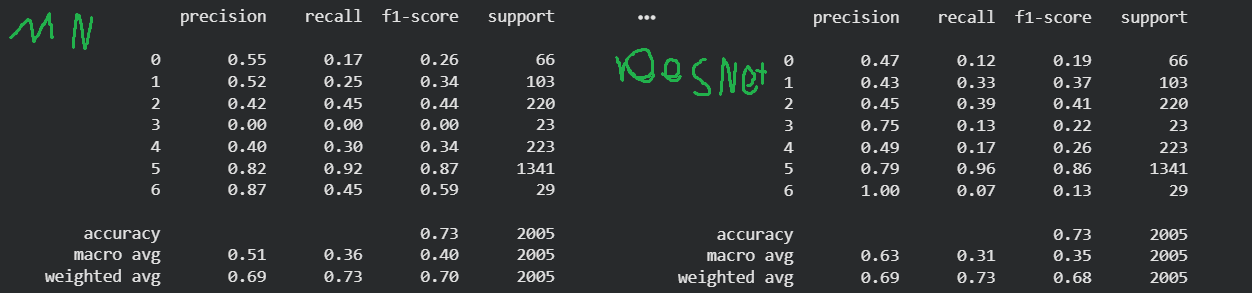

Overall, Resnet did a better job than Mobilenet. For example, look at label 3 or other labels. It spreads it's power over all of them but Mobilenet focuses mostly on the most repeated data and label.
Not forgeting the fact that MobileNet is exteremely faster than Resnet, in training and testing.